In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import ToTensor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import flwr as fl

## Handling the dataset

In [2]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor() # scaling the pixel values from 0 -> 255 to 0 -> 1
)

print(len(training_data))

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

print(len(test_data))

60000
10000


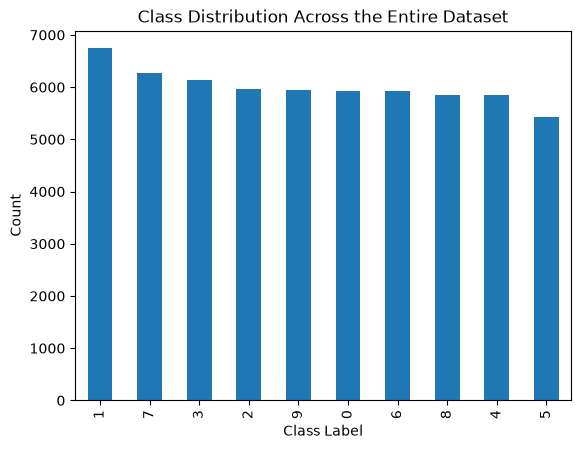

In [3]:
all_labels = []

for _, labels in training_data:
    all_labels.append(labels)

pd.Series(all_labels).value_counts().plot(kind="bar")
plt.title("Class Distribution Across the Entire Dataset")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

In [4]:
# This prints each digit and its exact count
counts = pd.Series(all_labels).value_counts()
print(counts)

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64


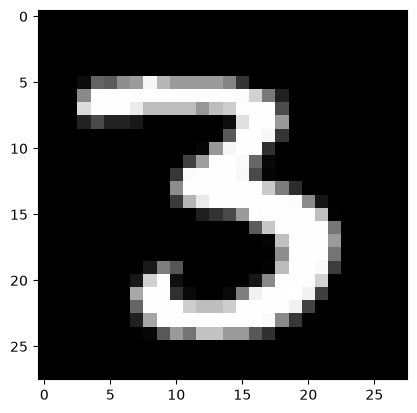

In [5]:
image_three, label_three = training_data[12]
image = image_three.unsqueeze(0)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

### Make the data for each client non-IID
- client1 - more data consisting of 0,1,2,3
- client2 - more data consisting of 4,5,6
- client3 - more data consisting of 7,8,9

Using **Dirichlet distribution**:
Dirichlet distribution is a standard method in machine learning, especially in Federated Learning (FL), to partition a centralized dataset into non-IID (non-independent and identically distributed) client splits

In [6]:
client1_train_data, client2_train_data, client3_train_data = random_split(
    training_data,
    [20000,20000,20000]
)

print(len(client1_train_data))
print(len(client2_train_data))
print(len(client3_train_data))

20000
20000
20000


In [7]:
client1_test_data, client2_test_data, client3_test_data = random_split(
    test_data,
    [3333,3333,3334]
)

print(len(client1_test_data))
print(len(client2_test_data))
print(len(client3_test_data))

3333
3333
3334


In [8]:
# dataloader
def create_dataloaders(train_data, test_data):
    train_data_loader = DataLoader(
        train_data,
        batch_size=64,
        shuffle=True
    )

    test_data_loader = DataLoader(
        test_data,
        batch_size=64,
        shuffle=True
    )

    return train_data_loader, test_data_loader

In [9]:
client1_train_loader, client1_test_loader = create_dataloaders (
    client1_train_data,
    client1_test_data
)

client2_train_loader, client2_test_loader = create_dataloaders (
    client2_train_data,
    client2_test_data
)

client3_train_loader, client3_test_loader = create_dataloaders (
    client3_train_data,
    client3_test_data
)

In [10]:
images, labels = next(iter(client1_train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        # flatten layer
        # self.flatten = nn.flatten() # input [1,28,28] flattened input 1x28x28 = 784
        
        # define linear layers
        self.fcl1 = nn.Linear(784,128)
        self.fcl2 = nn.Linear(128,64)
        self.fcl3 = nn.Linear(64, 10)

    def forward(self,x):
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

### Minimal Federated learning model
without using flower 

Training each client, with a leanrning rate of 0.005 and Adam optimiser:
| Client   | Accuracy | Precison | Recall   | F1-score  | Loss      |
| -------- | -------- | -------- | -------- |  -------- |  -------- |
| Client 1 | 95.65%   |          |          |           |   0.16    |
| Client 2 | 95.34%   |          |          |           |   0.15    |
| Client 3 | 95.80%   |          |          |           |   0.14    | 


In [12]:
global_model = MLP()

client1_model = MLP()
client2_model = MLP()
client3_model = MLP()

In [13]:
loss_function = nn.CrossEntropyLoss() 

# define each models own optimiser 
client1_optimiser = optim.Adam(
    client1_model.parameters(), 
    lr=0.005
)

client2_optimiser = optim.Adam(
    client2_model.parameters(), 
    lr=0.005
)

client3_optimiser = optim.Adam(
    client3_model.parameters(), 
    lr=0.005
)

In [14]:
def train_client(epochs, client, loader, loss_function, optimiser, model):
    for epoch in range(epochs):
        print(f"{client}: Starting training for epoch {epoch} ...")
    
        running_loss = 0.0
    
        for index, data in enumerate(loader):
            inputs, label = data
    
            optimiser.zero_grad()
            
            outputs = model(inputs)
    
            loss = loss_function(outputs, label)
            loss.backward()
            optimiser.step()
    
            running_loss += loss.item()
    
        print(f'{client}:Loss: {running_loss / len(loader):.4f}')
    return model
        
    #torch.save(model.state_dict(), f'trained_{client}_mlp.pth')

In [15]:
def test_client(client, model, loader):
    
    model.eval()

    # test the model
    correct = 0
    running_loss = 0
    total = 0

    all_labels, all_predicted = [], []
    
    with torch.no_grad():
        for index, data in enumerate(loader):
            inputs, label = data
    
            outputs = model(inputs)
    
            _, predicted = torch.max(outputs, 1)
            total += label.size(0)

            loss = loss_function(outputs, label)
            running_loss += loss.item()
            
            correct += (predicted == label).sum().item()

            all_predicted.extend(predicted)
            all_labels.extend(label)
            
    
    accuracy = 100* correct / total
    average_loss = running_loss / len(loader)
    
    print(f'{client} test accuracy: {accuracy}%')
    print(f'{client} test loss: {average_loss}')
    return accuracy, all_labels, all_predicted

In [16]:
def evaluate_client(client, y_true, y_pred):
    cr = classification_report(y_true, y_pred)
    print(f"{client} classification report")
    print("\n",cr)

    cm = confusion_matrix(y_true, y_pred)
    display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
    display_cm.plot()

    plt.show()
    
    

### Client 1

### Client 2

### Client 3

## FedAvg

https://medium.com/@joemuthui18/day-2-understanding-and-implementing-federated-averaging-fedavg-e8d1d523b155

In [17]:
def server_fedAvg(client_sizes, client_weights):
    total_size = sum(client_sizes)

    aggregated_weights = {}

    keys = client_weights[0].keys()

    for key in keys:
        for client, size in zip(client_weights, client_sizes):
            fraction = size / total_size
            if key not in aggregated_weights:
                aggregated_weights[key] = client[key] * fraction
            else:
                aggregated_weights[key] += client[key] * fraction
    return aggregated_weights
    

## Federated learning rounds

In [18]:
def federated_round(round_number):
    print(f"\n--- Federated Round {round_number} ---")

    # 1. Send the current global weights to every client
    client1_model.load_state_dict(global_model.state_dict())
    client2_model.load_state_dict(global_model.state_dict())
    client3_model.load_state_dict(global_model.state_dict())

    # 2. Train each client locally
    print(f"\n--- Training Client 1 ---")
    train_client(3, "Client 1", client1_train_loader,
                 loss_function, client1_optimiser, client1_model)

    print(f"\n--- Training Client 2 ---")
    train_client(3, "Client 2", client2_train_loader,
                 loss_function, client2_optimiser, client2_model)

    print(f"\n--- Training Client 2 ---")
    train_client(3, "Client 3", client3_train_loader,
                 loss_function, client3_optimiser, client3_model)

    # 3. Collect updated client weights
    client_weights = [
        client1_model.state_dict(),
        client2_model.state_dict(),
        client3_model.state_dict()
    ]

    client_sizes = [
        len(client1_train_loader.dataset),
        len(client2_train_loader.dataset),
        len(client3_train_loader.dataset)
    ]

    # 4. Aggregate the client weights
    aggregated_weights = server_fedAvg(client_sizes, client_weights)

    # 5. Update the global model
    global_model.load_state_dict(aggregated_weights)

    # 6. Evaluate the global model on each client's local test data
    print(f"\n--- Evaluating Client 1 ---")
    test_client("Client 1", global_model, client1_test_loader)
    print(f"\n--- Evaluating Client 2 ---")
    test_client("Client 2", global_model, client2_test_loader)
    print(f"\n--- Evaluating Client 3 ---")
    test_client("Client 3", global_model, client3_test_loader)

In [19]:
for round_number in range(1, 7):
    federated_round(round_number)


--- Federated Round 1 ---

--- Training Client 1 ---
Client 1: Starting training for epoch 0 ...
Client 1:Loss: 0.3598
Client 1: Starting training for epoch 1 ...
Client 1:Loss: 0.1516
Client 1: Starting training for epoch 2 ...
Client 1:Loss: 0.1071

--- Training Client 2 ---
Client 2: Starting training for epoch 0 ...
Client 2:Loss: 0.3703
Client 2: Starting training for epoch 1 ...
Client 2:Loss: 0.1474
Client 2: Starting training for epoch 2 ...
Client 2:Loss: 0.1005

--- Training Client 2 ---
Client 3: Starting training for epoch 0 ...
Client 3:Loss: 0.3681
Client 3: Starting training for epoch 1 ...
Client 3:Loss: 0.1638
Client 3: Starting training for epoch 2 ...
Client 3:Loss: 0.1126

--- Evaluating Client 1 ---
Client 1 test accuracy: 95.4095409540954%
Client 1 test loss: 0.20840272096530446

--- Evaluating Client 2 ---
Client 2 test accuracy: 94.92949294929493%
Client 2 test loss: 0.2139487125963535

--- Evaluating Client 3 ---
Client 3 test accuracy: 95.08098380323935%
Clie

Predicted: 7
Actual: 7


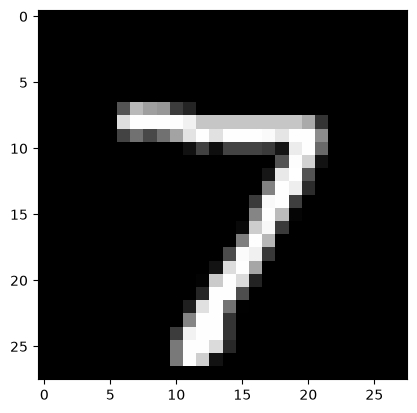

Predicted: 2
Actual: 2


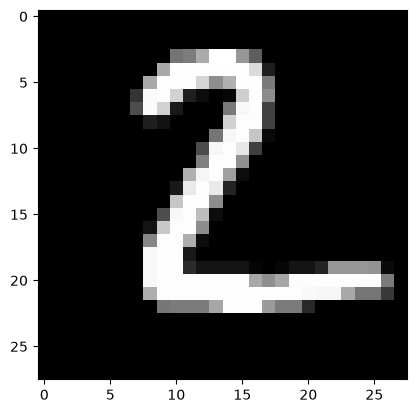

Predicted: 1
Actual: 1


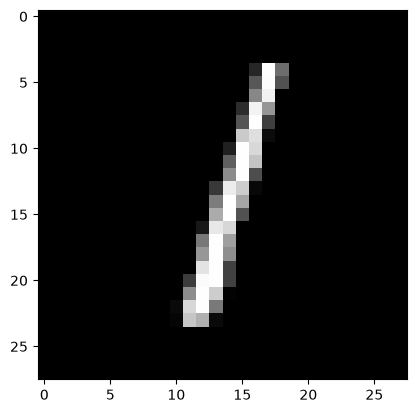

Predicted: 0
Actual: 0


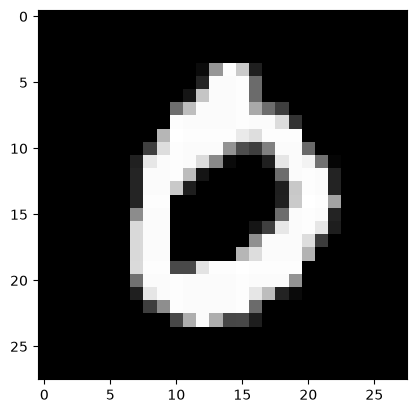

Predicted: 4
Actual: 4


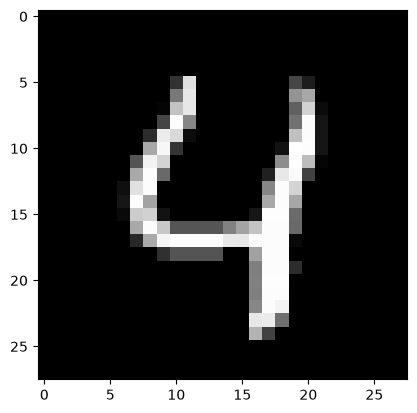

Predicted: 1
Actual: 1


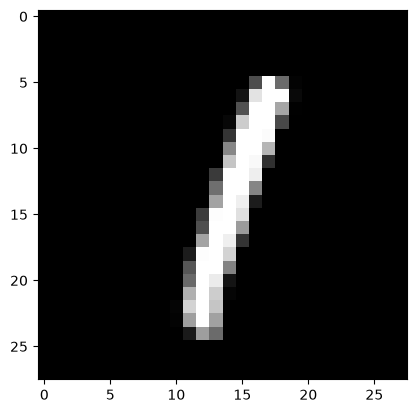

Predicted: 4
Actual: 4


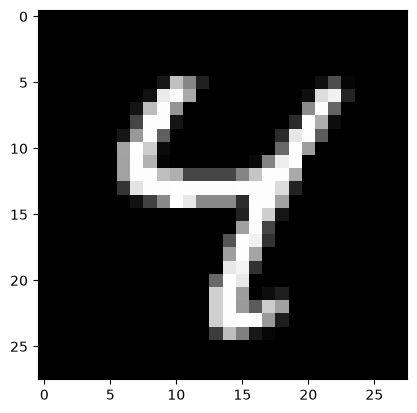

Predicted: 9
Actual: 9


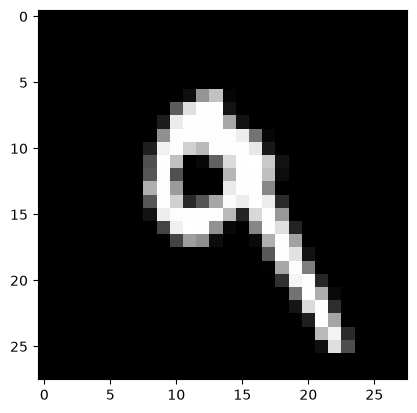

Predicted: 5
Actual: 5


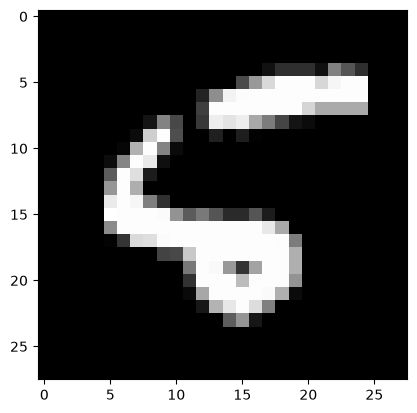

Predicted: 9
Actual: 9


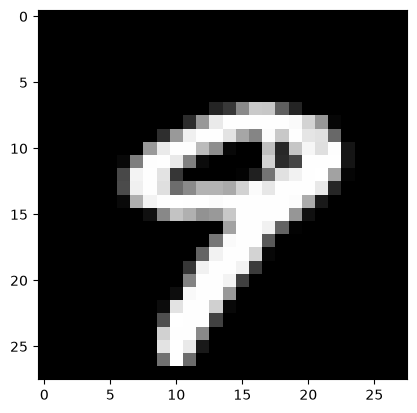

Predicted: 0
Actual: 0


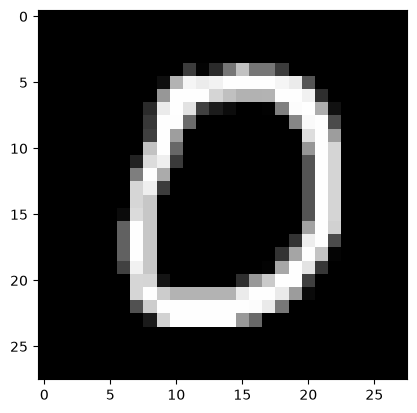

Predicted: 6
Actual: 6


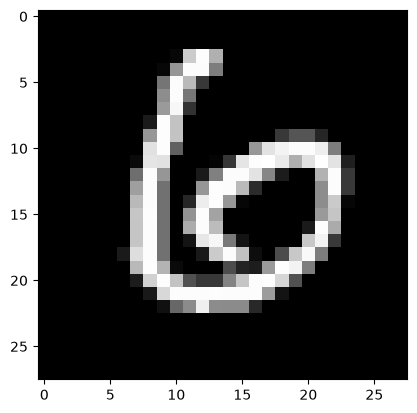

Predicted: 9
Actual: 9


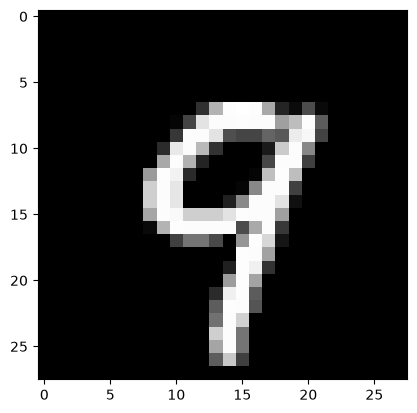

Predicted: 0
Actual: 0


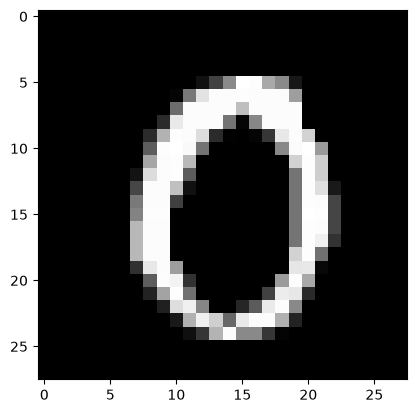

Predicted: 1
Actual: 1


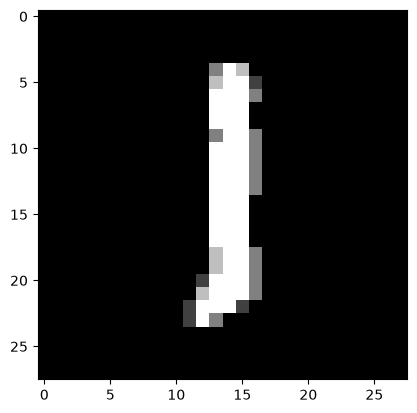

Predicted: 5
Actual: 5


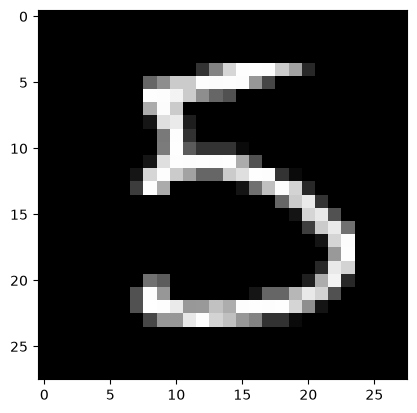

Predicted: 9
Actual: 9


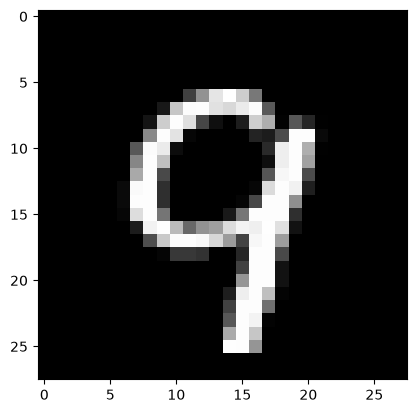

Predicted: 7
Actual: 7


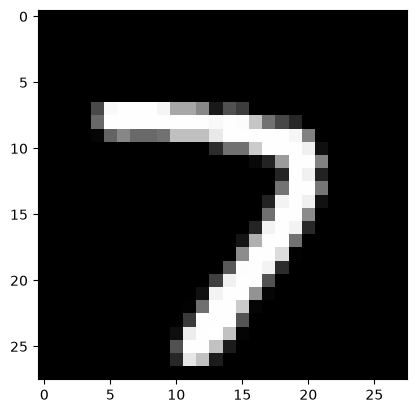

Predicted: 3
Actual: 3


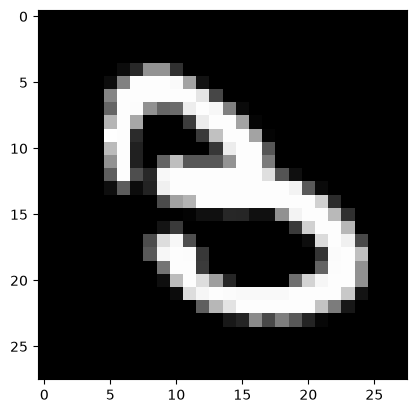

Predicted: 4
Actual: 4


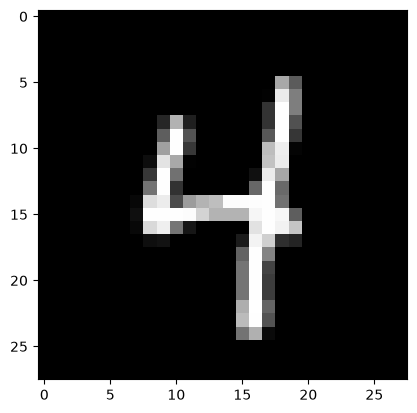

In [20]:
global_model.eval()

for i in range(20):
    image, label = test_data[i]
    with torch.no_grad():
        output = global_model(image.unsqueeze(0))
        _,predicted = torch.max(output,1)
    
    print("Predicted:", predicted.item())
    print("Actual:", label)
    
    plt.imshow(image.squeeze(), cmap="gray")
    plt.show()